In [1]:
cd ..

c:\Users\tangr\OneDrive - unine.ch\ERCKarst\pc-centrelines


In [2]:
conduit_map = {
    1:"straight_cyl",
    2:"straight_elp",
    3: "wavy",
    4:"rough",
    5:"sinu_1",
    6:"sinu_2",
    7:"branching",
    8:"meandre",
    9:"motiers",
    10:"faux_monnayeurs"
    }


In [3]:
# yaml processing file loading. 
import yaml
import numpy as np
import matplotlib.pyplot as plt
from os.path import exists, split, join, normpath, isdir
from os import listdir, makedirs

from stl import mesh
import pyvista as pv
# for the triangle adjacency matrix.
from base.utils import find_neighbours_with_knn
# for laplacian based contraction
from base.LBC_centreline import return_LBC_centreline
# for the iterative path finder
from base import iterative_section_minimiser
# for the maximum spanning tree clearance method
from base.MST_centreline import return_MST_centrelines
from base.iterative_section_minimiser import mesh_intersect
from base.geometry import to2D

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


In [4]:
with open(f"./notebooks/plot_kwargs.yaml", "r") as f: 
    p = yaml.safe_load(f)
    f.close()

In [5]:
skeleton_kwargs = p["skeleton_kwargs"]
node_kwargs = p["node_kwargs"]
ct_kwargs = p["ct_kwargs"]
ct_1_kwargs = p["ct1_kwargs"]
ct_2_kwargs = p["ct2_kwargs"]
mesh_kwargs = p["mesh_kwargs"]
start_kwargs = p["start_kwargs"]
end_kwargs = p["end_kwargs"]
section_node_kwargs = p["section_node_kwargs"]

In [6]:
# list all the lbc centrelines and plot in a 3x3 matrix. 

In [7]:
# list all meshes. 
list_meshes = []
for k, (conduit_id, conduit_name) in enumerate(conduit_map.items()):
    mesh_fp = f"./data/{conduit_id}_{conduit_name}/{conduit_name}.stl"
    list_meshes.append(mesh.Mesh.from_file(mesh_fp))

In [8]:
# list all lbc centrelines, the sources and the target points
list_lbc_ct = []

for k, (conduit_id, conduit_name) in enumerate(conduit_map.items()):
    lbc_ct_fp = f"./temp/{conduit_id}_{conduit_name}/lbc/{conduit_name}_centreline.txt"

    lbc_ct = np.loadtxt(lbc_ct_fp)
    print(lbc_ct_fp)
    
    print(np.mean(lbc_ct, axis = 0)) 
    P1 = lbc_ct[0]
    P2 = lbc_ct[-1]

    list_lbc_ct.append((lbc_ct, P1, P2))

./temp/1_straight_cyl/lbc/straight_cyl_centreline.txt
[-0.09023493 -0.00130173 -0.00120165]
./temp/2_straight_elp/lbc/straight_elp_centreline.txt
[-0.03981244 -0.00026305 -0.00048091]
./temp/3_wavy/lbc/wavy_centreline.txt
[ 0.06889285 -0.04639907 -0.04813331]
./temp/4_rough/lbc/rough_centreline.txt
[-0.13884362 -0.05456385 -0.0313172 ]
./temp/5_sinu_1/lbc/sinu_1_centreline.txt
[-0.03800332  0.02957563 -0.00301788]
./temp/6_sinu_2/lbc/sinu_2_centreline.txt
[ 0.02515956  0.03013049 -0.00011734]
./temp/7_branching/lbc/branching_centreline.txt
[-0.12544644  0.05777967  0.00821553]
./temp/8_meandre/lbc/meandre_centreline.txt
[-0.86822356  0.38073797 -0.96644295]
./temp/9_motiers/lbc/motiers_centreline.txt
[ 0.70410549 -0.61561894 -0.31817571]
./temp/10_faux_monnayeurs/lbc/faux_monnayeurs_centreline.txt
[-0.61690222  0.02522373 -1.52811853]


In [9]:
section_ids = {
    1:[10],
    2:[10],
    3:[6],
    4:[5],
    5:[7],
    6:[7,20],
    7:[7,15],
    8:[15, 30],
    9:[15, 30],
    10:[15, 30]
}

troubleshooting:   [1.0372143e+00 8.2506000e-05 0.0000000e+00] [1.0372143e+00 8.2506000e-05 3.1536120e-04] 1.0372143032815013 1.0372143512237075
troubleshooting:   [0 1 0] [1.0372143e+00 8.2506000e-05 0.0000000e+00] 1.0 1.0372143032815013
troubleshooting:   [-9.329195e-01 -9.555780e-05  0.000000e+00] [-9.329195e-01 -9.555780e-05  5.476660e-05] 0.932919504893934 0.9329195065014577
troubleshooting:   [0 1 0] [-9.329195e-01 -9.555780e-05  0.000000e+00] 1.0 0.932919504893934
troubleshooting:   [ 1.0769945 -0.0022553  0.       ] [ 1.0769945e+00 -2.2553000e-03  1.8111000e-04] 1.0769968613734862 1.0769968766014004
troubleshooting:   [0 1 0] [ 1.0769945 -0.0022553  0.       ] 1.0 1.0769968613734862
troubleshooting:   [1.0150475e+00 2.6935000e-04 0.0000000e+00] [1.0150475e+00 2.6935000e-04 3.5755130e-02] 1.0150475357369586 1.015677079158031
troubleshooting:   [0 1 0] [1.0150475e+00 2.6935000e-04 0.0000000e+00] 1.0 1.0150475357369586
troubleshooting:   [-0.691934 -0.18097   0.      ] [-6.91934e-

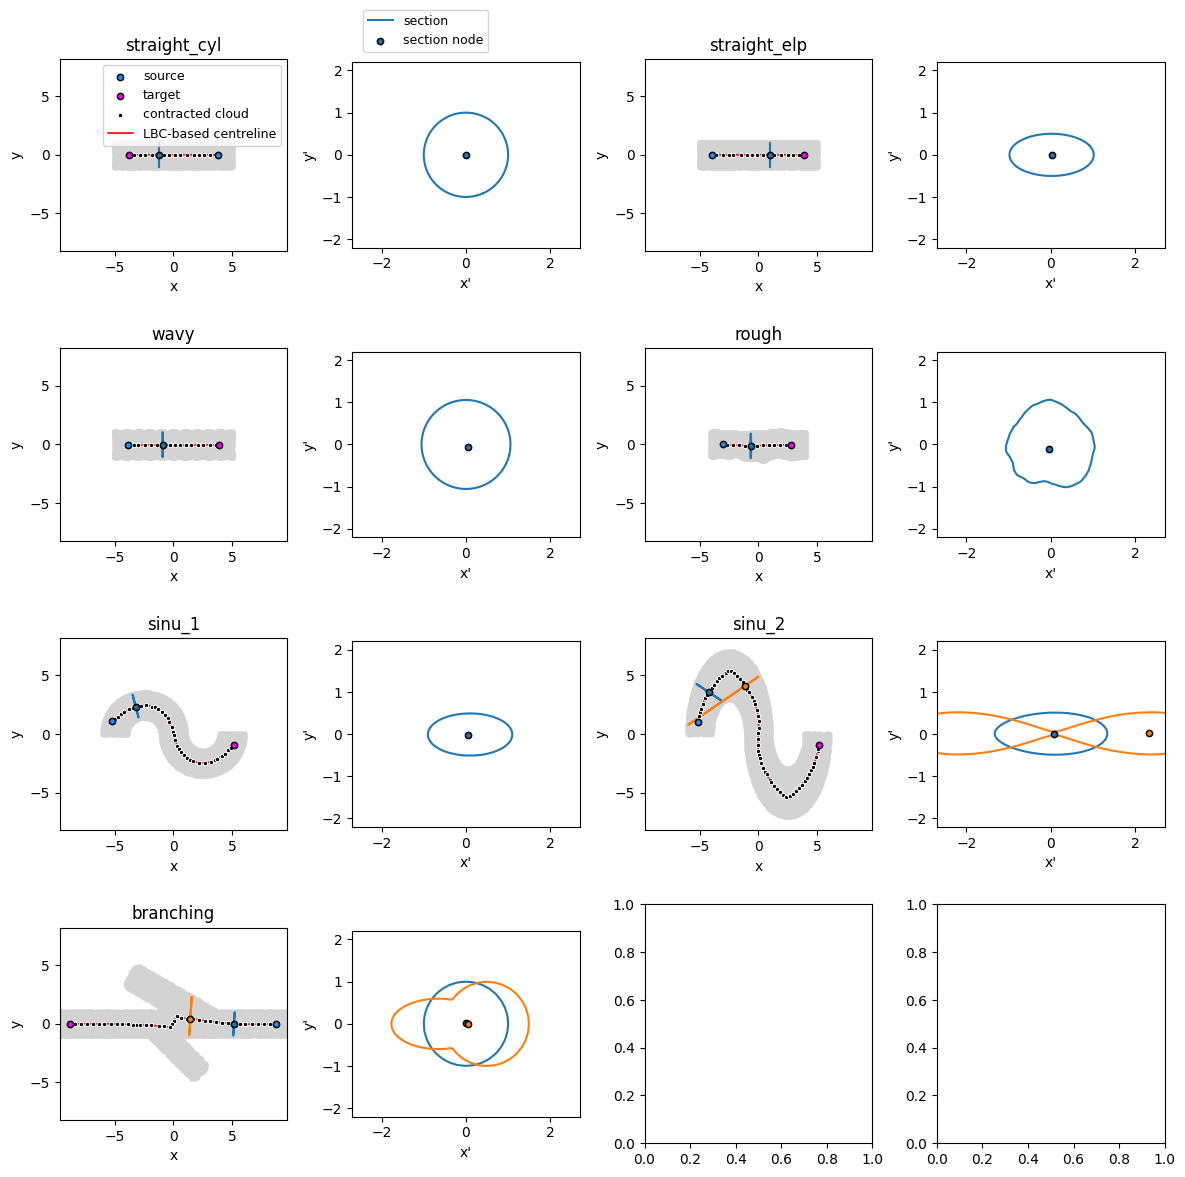

In [10]:
fig, axes = plt.subplots(4,4, figsize=(12,12))

for k, (lbc, P1, P2) in enumerate(list_lbc_ct):
    if k < 7:
        ax = axes.flatten()[2*k]
        ax.scatter(*P1[[0, 1]], **start_kwargs)
        ax.scatter(*P2[[0, 1]], **end_kwargs)
        ax.scatter(*lbc[:,[0, 1]].T, **node_kwargs,label = "contracted cloud")
        ax.plot(*lbc[:,[0, 1]].T, **ct_kwargs, label = "LBC-based centreline")
        ax.set_title(conduit_map[k+1])
        if k == 0:  
            ax.legend(fontsize=9)


for k, themesh in enumerate(list_meshes):
    if k < 7:
        ax= axes.flatten()[2*k]

        ax.scatter(*themesh[::50, [0,1]].T, **mesh_kwargs)
        ax.set_aspect("equal")
        ax.set_xlim(-9.7, 9.7)
        ax.set_ylim(-8.2, 8.2)
        ax.set_xlabel("x")
        ax.set_ylabel("y")
    # plot a section only. or several. 

for k, (themesh, (lbc, P1, P2)) in enumerate(zip(list_meshes,list_lbc_ct)):
    if k < 7:
        ax = axes.flatten()[2*k]

        ax2 = axes.flatten()[2*k+1]
        thesections = section_ids[k+1]
        for thesection in thesections:
            sectionvec = lbc[thesection+1] - lbc[thesection-1]
            intersect = mesh_intersect(themesh, lbc[thesection], sectionvec)
            polyline3d = intersect[0]
            ax.plot(*polyline3d[:, [0, 1]].T)
            ax.scatter(*lbc[thesection][[0,1]].T,  **section_node_kwargs)

            section2d, R1, R2 = to2D(polyline3d, sectionvec, returnTransform=True)
            ax2.plot(*section2d.T, label = "section")

            rotdiff = R2 @ (R1 @ (np.mean(polyline3d, axis = 0)))
            rotinit = R2 @ R1 @ lbc[thesection]
            #print(rotdiff, rotinit, rotinit - rotdiff)
            ax2.scatter(*(rotinit - rotdiff)[[0,2]].T,  **section_node_kwargs)
            ax2.set_aspect(True)
            if k == 0:
                ax2.legend(fontsize=9, loc = "lower left", bbox_to_anchor=(0.02, 1.02))

        ax2.set_xlim(-2.7, 2.7)
        ax2.set_ylim(-2.2, 2.2)
        ax2.set_xlabel("x'")
        ax2.set_ylabel("y'")

        

plt.tight_layout()
plt.savefig("./temp/figures/summary_synthetic_LBC.png", dpi=300)
plt.show()


### real caves. 

sections:  [15, 30]
troubleshooting:   [-2.089539   0.1793961  0.       ] [-2.089539   0.1793961  0.221679 ] 2.0972258326694844 2.1089091427221827
troubleshooting:   [0 1 0] [-2.089539   0.1793961  0.       ] 1.0 2.0972258326694844
troubleshooting:   [-2.006766   0.2478324  0.       ] [-2.006766   0.2478324  0.1386084] 2.022011542312693 2.026756760392405
troubleshooting:   [0 1 0] [-2.006766   0.2478324  0.       ] 1.0 2.022011542312693
sections:  [15, 30]
troubleshooting:   [-1.77473    0.0257553  0.       ] [-1.77473    0.0257553  0.541351 ] 1.774916873652986 1.8556375760312382
troubleshooting:   [0 1 0] [-1.77473    0.0257553  0.       ] 1.0 1.774916873652986
troubleshooting:   [-1.0798046 -0.0447015  0.       ] [-1.0798046  -0.0447015   0.31031927] 1.0807294750692282 1.1243995053435156
troubleshooting:   [0 1 0] [-1.0798046 -0.0447015  0.       ] 1.0 1.0807294750692282
sections:  [15, 30]
troubleshooting:   [ 1.5078   -0.343339  0.      ] [ 1.5078   -0.343339  0.007909] 1.546396620

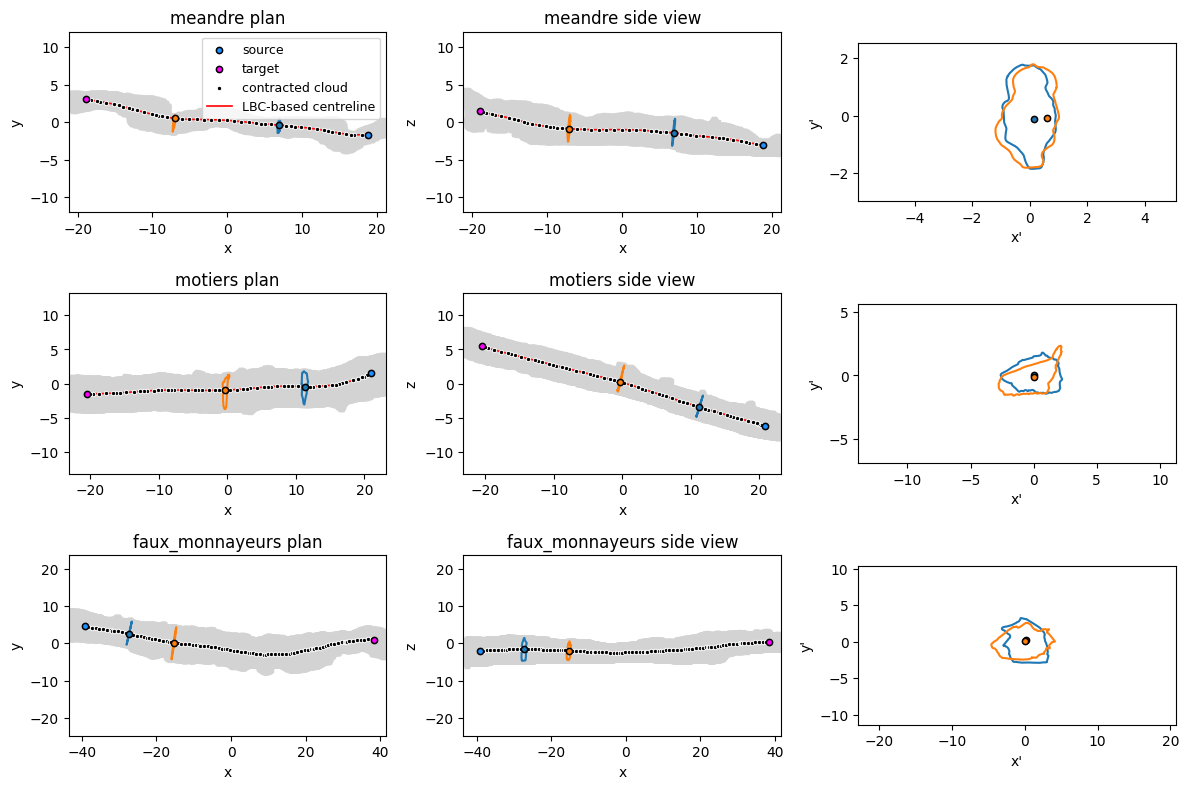

In [14]:
fig, axes = plt.subplots(3,3, figsize=(12,8))

for k, (lbc, P1, P2) in enumerate(list_lbc_ct):
    if k >= 7:
        k1 = k-7
        ax = axes.flatten()[3*k1]
        ax.scatter(*P1[[0, 1]], **start_kwargs)
        ax.scatter(*P2[[0, 1]], **end_kwargs)
        ax.scatter(*lbc[:,[0, 1]].T, **node_kwargs,label = "contracted cloud")
        ax.plot(*lbc[:,[0, 1]].T, **ct_kwargs, label = "LBC-based centreline")
        ax.set_title(f"{conduit_map[k+1]} plan")
        if k1 == 0:  
            ax.legend(fontsize=9)
        
        ax2 = axes.flatten()[3*k1+1]
        ax2.scatter(*P1[[0, 2]], **start_kwargs)
        ax2.scatter(*P2[[0, 2]], **end_kwargs)
        ax2.scatter(*lbc[:,[0, 2]].T, **node_kwargs,label = "contracted cloud")
        ax2.plot(*lbc[:,[0, 2]].T, **ct_kwargs, label = "LBC-based centreline")
        ax2.set_title(f"{conduit_map[k+1]} side view")


for k, themesh in enumerate(list_meshes):
    if k >= 7:
        k1= k-7
        ax= axes.flatten()[3*k1]

        ax.scatter(*themesh[::50, [0,1]].T, **mesh_kwargs)
        ax.set_aspect("equal")
        xmin = np.min(themesh[:, 0])
        xmax = np.max(themesh[:, 0])
        ax.set_xlim(1.02*xmin,1.02*xmax)
        ax.set_ylim(0.58*xmin,0.58*xmax)
        ax.set_xlabel("x")
        ax.set_ylabel("y")

        ax2= axes.flatten()[3*k1+1]

        ax2.scatter(*themesh[::50, [0,2]].T, **mesh_kwargs)
        ax2.set_aspect("equal")
        xmin = np.min(themesh[:, 0])
        xmax = np.max(themesh[:, 0])
        ax2.set_xlim(1.02*xmin,1.02*xmax)
        ax2.set_ylim(0.58*xmin,0.58*xmax)
        ax2.set_xlabel("x")
        ax2.set_ylabel("z")


    # plot a section only. or several. 

for k, (themesh, (lbc, P1, P2)) in enumerate(zip(list_meshes,list_lbc_ct)):
    if k >= 7:
        k1 = k-7
        ax = axes.flatten()[3*k1]
        ax2 = axes.flatten()[3*k1+1]
        ax3 = axes.flatten()[3*k1+2]
        thesections = section_ids[k+1]
        print("sections: ", thesections)
        
        x2min = 0 
        x2max = 0
        for thesection in thesections:
            sectionvec = lbc[thesection+1] - lbc[thesection-1]
            intersect = mesh_intersect(themesh, lbc[thesection], sectionvec)
            polyline3d = intersect[0]
            ax.plot(*polyline3d[:, [0, 1]].T)
            ax.scatter(*lbc[thesection][[0,1]].T,  **section_node_kwargs)
            ax2.plot(*polyline3d[:, [0, 2]].T)
            ax2.scatter(*lbc[thesection][[0,2]].T,  **section_node_kwargs)

            section2d, R1, R2 = to2D(polyline3d, sectionvec, returnTransform=True)
            ax3.plot(*section2d.T, label = "section")

            rotdiff = R2 @ (R1 @ (np.mean(polyline3d, axis = 0)))
            rotinit = R2 @ R1 @ lbc[thesection]
            #print(rotdiff, rotinit, rotinit - rotdiff)
            ax3.scatter(*(rotinit - rotdiff)[[0,2]].T,  **section_node_kwargs)
            ax3.set_aspect(True)
            if k == 0:
                ax3.legend(fontsize=9, loc = "lower left", bbox_to_anchor=(0.02, 1.02))

            ## update the bounds. 
            x2min_n, x2max_n = np.min(section2d[:, 0]), np.max(section2d[:, 0])
            if x2min_n < x2min:
                x2min = x2min_n.copy()


            if x2max_n > x2max:
                x2max = x2max_n.copy()

        ax3.set_xlim(5*x2min,5*x2max)
        ax3.set_ylim(2.5*x2min,2.5*x2max)
        ax3.set_xlabel("x'")
        ax3.set_ylabel("y'")

        

plt.tight_layout()
plt.savefig("./temp/figures/summary_real_LBC.png", dpi=300)
plt.show()


## Minimum spanning tree centrelines.

In [15]:
# list all lbc centrelines, the sources and the target points
list_mst_ct = []
for k, (conduit_id, conduit_name) in enumerate(conduit_map.items()):
    delta = 200
    if k >= 7:
        # real conduits have a different delta, because larger files. 
        delta = 400
    
    mst_ct_fp = f"./temp/{conduit_id}_{conduit_name}/mst/{conduit_name}_{delta}_centerspline-simplified.txt"
    
    try: 
        mst_ct = np.loadtxt(mst_ct_fp)
    except FileNotFoundError:
        mst_ct = np.loadtxt(f"./temp/{conduit_id}_{conduit_name}/mst/{conduit_name}_{delta}_centerspline-direct.txt")
    print(mst_ct_fp)
    print(np.mean(mst_ct, axis = 0)) 
    P1 = mst_ct[0]
    P2 = mst_ct[-1]

    list_mst_ct.append((mst_ct, P1, P2))

./temp/1_straight_cyl/mst/straight_cyl_200_centerspline-simplified.txt
[1.42547154e-16 0.00000000e+00 0.00000000e+00]
./temp/2_straight_elp/mst/straight_elp_200_centerspline-simplified.txt
[-0.1075  0.      0.    ]
./temp/3_wavy/mst/wavy_200_centerspline-simplified.txt
[-1.42547154e-16  0.00000000e+00  0.00000000e+00]
./temp/4_rough/mst/rough_200_centerspline-simplified.txt
[-0.09999994  0.          0.        ]
./temp/5_sinu_1/mst/sinu_1_200_centerspline-simplified.txt
[0.03110055 0.0149297  0.        ]
./temp/6_sinu_2/mst/sinu_2_200_centerspline-simplified.txt
[ 2.62085435e-17 -1.83459805e-16  0.00000000e+00]
./temp/7_branching/mst/branching_200_centerspline-simplified.txt
[-6.79945202e-17  0.00000000e+00  0.00000000e+00]
./temp/8_meandre/mst/meandre_400_centerspline-simplified.txt
[-0.2144921   0.30350226 -1.06229359]
./temp/9_motiers/mst/motiers_400_centerspline-simplified.txt
[ 0.3300083  -0.28121192 -0.08531957]
./temp/10_faux_monnayeurs/mst/faux_monnayeurs_400_centerspline-simpli

In [16]:
section_ids_mst = {
    1:[50],
    2:[50],
    3:[50],
    4:[50],
    5:[37],
    6:[37],
    7:[37],
    8:[250, 500],
    9:[250, 500],
    10:[250, 500]
}

[-1.  0.  0.]
[1. 0. 0.]
[1. 0. 0.]
[1. 0. 0.]
[0.95315827 0.30247201 0.        ]
[0.61157582 0.79118583 0.        ]
troubleshooting:   [0.61157582 0.79118583 0.        ] [0.61157582 0.79118583 0.        ] 1.0 1.0
troubleshooting:   [0 1 0] [0.61157582 0.79118583 0.        ] 1.0 1.0
[-1.  0.  0.]
troubleshooting:   [-1.  0.  0.] [-1.  0.  0.] 1.0 1.0
troubleshooting:   [0 1 0] [-1.  0.  0.] 1.0 1.0


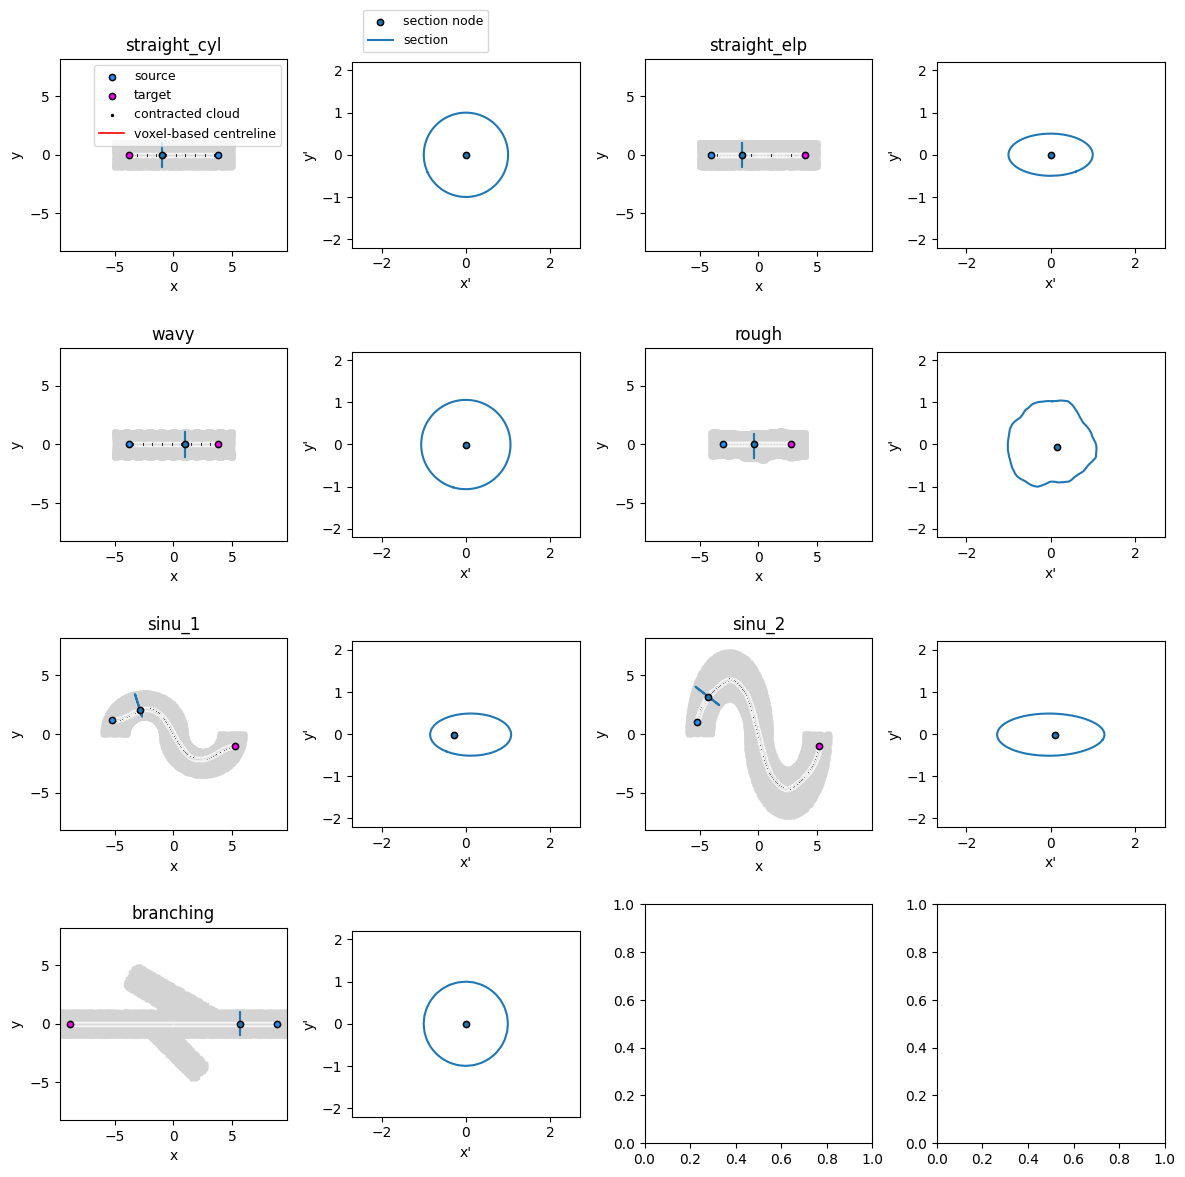

In [17]:
fig, axes = plt.subplots(4,4, figsize=(12,12))

for k, (mst, P1, P2) in enumerate(list_mst_ct):
    if k < 7:
        ax = axes.flatten()[2*k]
        ax.scatter(*P1[[0, 1]], **start_kwargs)
        ax.scatter(*P2[[0, 1]], **end_kwargs)
        ax.scatter(*mst[:,[0, 1]].T, **node_kwargs,label = "contracted cloud")
        ax.plot(*mst[:,[0, 1]].T, **ct_kwargs, label = "voxel-based centreline")
        ax.set_title(conduit_map[k+1])
        if k == 0:  
            ax.legend(fontsize=9)


for k, themesh in enumerate(list_meshes):
    if k < 7:
        ax= axes.flatten()[2*k]

        ax.scatter(*themesh[::50, [0,1]].T, **mesh_kwargs)
        ax.set_aspect("equal")
        ax.set_xlim(-9.7, 9.7)
        ax.set_ylim(-8.2, 8.2)
        ax.set_xlabel("x")
        ax.set_ylabel("y")
    # plot a section only. or several. 

for k, (themesh, (mst, P1, P2)) in enumerate(zip(list_meshes,list_mst_ct)):
    if k < 7:
        ax = axes.flatten()[2*k]

        ax2 = axes.flatten()[2*k+1]
        thesections = section_ids_mst[k+1]
        for thesection in thesections:
            sectionvec = mst[thesection+1] - mst[thesection-1]
            sectionvec /= np.linalg.norm(sectionvec)
            print(sectionvec)
            intersect = mesh_intersect(themesh, mst[thesection], sectionvec)
            polyline3d = intersect[0]
            ax.plot(*(polyline3d[:, [0, 1]]).T)
            ax.scatter(*mst[thesection][[0,1]].T,  **section_node_kwargs)
            if k<= 4:
                section2d = (polyline3d - np.mean(polyline3d, axis=0))[:, [1,2]]
                ax2.scatter(*(mst[thesection]- np.mean(polyline3d, axis=0))[[1,2]], **section_node_kwargs)
            else:
                section2d, R1, R2 = to2D(polyline3d, sectionvec, returnTransform=True)
            

                rotdiff = R2 @ (R1 @ (np.mean(polyline3d, axis = 0)))
                rotinit = R2 @ R1 @ mst[thesection]
                ax2.scatter(*(rotinit - rotdiff)[[0,2]].T,  **section_node_kwargs)

            #print(rotdiff, rotinit, rotinit - rotdiff)
        
            ax2.plot(*section2d.T, label = "section")

            ax2.set_aspect(True)
            if k == 0:
                ax2.legend(fontsize=9, loc = "lower left", bbox_to_anchor=(0.02, 1.02))

        ax2.set_xlim(-2.7, 2.7)
        ax2.set_ylim(-2.2, 2.2)
        ax2.set_xlabel("x'")
        ax2.set_ylabel("y'")

    
plt.tight_layout()
plt.savefig("./temp/figures/summary_synthetic_MST.png", dpi=300)

plt.show()


### real caves

In [ ]:
fig, axes = plt.subplots(3,3, figsize=(12,8))

for k, (mst, P1, P2) in enumerate(list_mst_ct):
    if k >= 7:
        k1 = k-7
        ax = axes.flatten()[3*k1]
        ax.scatter(*P1[[0, 1]], **start_kwargs)
        ax.scatter(*P2[[0, 1]], **end_kwargs)
        ax.scatter(*mst[:,[0, 1]].T, **node_kwargs,label = "contracted cloud")
        ax.plot(*mst[:,[0, 1]].T, **ct_kwargs, label = "voxel-based centreline")
        ax.set_title(f"{conduit_map[k+1]} plan")
        if k1 == 0:  
            ax.legend(fontsize=9)
        
        ax2 = axes.flatten()[3*k1+1]
        ax2.scatter(*P1[[0, 2]], **start_kwargs)
        ax2.scatter(*P2[[0, 2]], **end_kwargs)
        ax2.scatter(*mst[:,[0, 2]].T, **node_kwargs,label = "contracted cloud")
        ax2.plot(*mst[:,[0, 2]].T, **ct_kwargs, label = "voxel-based centreline")
        ax2.set_title(f"{conduit_map[k+1]} side view")


for k, themesh in enumerate(list_meshes):
    if k >= 7:
        k1= k-7
        ax= axes.flatten()[3*k1]

        ax.scatter(*themesh[::50, [0,1]].T, **mesh_kwargs)
        ax.set_aspect("equal")
        xmin = np.min(themesh[:, 0])
        xmax = np.max(themesh[:, 0])
        ax.set_xlim(1.02*xmin,1.02*xmax)
        ax.set_ylim(0.58*xmin,0.58*xmax)
        ax.set_xlabel("x")
        ax.set_ylabel("y")

        ax2= axes.flatten()[3*k1+1]

        ax2.scatter(*themesh[::50, [0,2]].T, **mesh_kwargs)
        ax2.set_aspect("equal")
        xmin = np.min(themesh[:, 0])
        xmax = np.max(themesh[:, 0])
        ax2.set_xlim(1.02*xmin,1.02*xmax)
        ax2.set_ylim(0.58*xmin,0.58*xmax)
        ax2.set_xlabel("x")
        ax2.set_ylabel("z")


    # plot a section only. or several. 

for k, (themesh, (mst, P1, P2)) in enumerate(zip(list_meshes,list_mst_ct)):
    if k >= 7:
        k1 = k-7
        ax = axes.flatten()[3*k1]
        ax2 = axes.flatten()[3*k1+1]
        ax3 = axes.flatten()[3*k1+2]
        thesections = section_ids_mst[k1+1]
        
        
        x2min = 0 
        x2max = 0
        for thesection in thesections:
            sectionvec = mst[thesection+1] - mst[thesection-1]
            intersect = mesh_intersect(themesh, mst[thesection], sectionvec)
            polyline3d = intersect[0]
            ax.plot(*polyline3d[:, [0, 1]].T)
            ax.scatter(*mst[thesection][[0,1]].T,  **section_node_kwargs)
            ax2.plot(*polyline3d[:, [0, 2]].T)
            ax2.scatter(*mst[thesection][[0,2]].T,  **section_node_kwargs)

            section2d, R1, R2 = to2D(polyline3d, sectionvec, returnTransform=True)
            ax3.plot(*section2d.T, label = "section")

            rotdiff = R2 @ (R1 @ (np.mean(polyline3d, axis = 0)))
            rotinit = R2 @ R1 @ mst[thesection]
            #print(rotdiff, rotinit, rotinit - rotdiff)
            ax3.scatter(*(rotinit - rotdiff)[[0,2]].T,  **section_node_kwargs)
            ax3.set_aspect(True)
            if k == 0:
                ax3.legend(fontsize=9, loc = "lower left", bbox_to_anchor=(0.02, 1.02))

            ## update the bounds. 
            x2min_n, x2max_n = np.min(section2d[:, 0]), np.max(section2d[:, 0])
            if x2min_n < x2min:
                x2min = x2min_n.copy()


            if x2max_n > x2max:
                x2max = x2max_n.copy()

        ax3.set_xlim(5*x2min,5*x2max)
        ax3.set_ylim(2.5*x2min,2.5*x2max)
        ax3.set_xlabel("x'")
        ax3.set_ylabel("y'")

        

plt.tight_layout()
plt.savefig("./temp/figures/summary_real_MST.png", dpi=300)
plt.show()


## List all iterative centrelines

In [ ]:
# list all iterative centrelines, the sources and the target points
list_iter_ct = []
list_iter_norm = []

for k, (conduit_id, conduit_name) in enumerate(conduit_map.items()):
    iter_ct_fp = f"./temp/{conduit_id}_{conduit_name}/iterative/{conduit_name}_centreline.txt"
    iter_norm_fp = f"./temp/{conduit_id}_{conduit_name}/iterative/{conduit_name}_vectors.txt"

    iter_ct = np.loadtxt(iter_ct_fp)
    iter_norm = np.loadtxt(iter_norm_fp)
    print(iter_ct_fp)
    print(np.mean(iter_ct, axis = 0)) 
    P1 = iter_ct[0]
    P2 = iter_ct[-1]

    list_iter_ct.append((iter_ct, P1, P2))
    list_iter_norm.append(iter_norm)

In [ ]:
section_ids_iter = {
    1:[10],
    2:[10],
    3:[10],
    4:[10],
    5:[12],
    6:[6],
    7:[7],
    8:[20],
    9:[30],
    10:[40]
}

In [ ]:
fig, axes = plt.subplots(4,4, figsize=(12,12))

for k, (iter, P1, P2) in enumerate(list_iter_ct):
    if k <7:
        ax = axes.flatten()[2*k]
        ax.scatter(*P1[[0, 1]], **start_kwargs)
        ax.scatter(*P2[[0, 1]], **end_kwargs)
        ax.scatter(*iter[:,[0, 1]].T, **node_kwargs,label = "contracted cloud")
        ax.plot(*iter[:,[0, 1]].T, **ct_kwargs, label = "iterative centreline")
        ax.set_title(conduit_map[k+1])
        if k == 0:  
            ax.legend(fontsize=9)


for k, themesh in enumerate(list_meshes):
    if k < 7:
        ax= axes.flatten()[2*k]

        ax.scatter(*themesh[::50, [0,1]].T, **mesh_kwargs)
        ax.set_aspect("equal")
        ax.set_xlim(-9.7, 9.7)
        ax.set_ylim(-8.2, 8.2)
        ax.set_xlabel("x")
        ax.set_ylabel("y")
    # plot a section only. or several. 

for k, (themesh, (iter, P1, P2), thenorm) in enumerate(zip(list_meshes,list_iter_ct, list_iter_norm)):
    if k < 7:
        ax = axes.flatten()[2*k]

        ax2 = axes.flatten()[2*k+1]
        thesections = section_ids_iter[k+1]
        for thesection in thesections:
            sectionvec = thenorm[thesection]
            intersect = mesh_intersect(themesh, iter[thesection], sectionvec)
            polyline3d = intersect[0]
            ax.plot(*polyline3d[:, [0, 1]].T)
            ax.scatter(*iter[thesection][[0,1]].T,  **section_node_kwargs)

            section2d, R1, R2 = to2D(polyline3d, sectionvec, returnTransform=True)
            ax2.plot(*section2d.T, label = "section")

            rotdiff = R2 @ (R1 @ (np.mean(polyline3d, axis = 0)))
            rotinit = R2 @ R1 @ iter[thesection]
            #print(rotdiff, rotinit, rotinit - rotdiff)
            ax2.scatter(*(rotinit - rotdiff)[[0,2]].T,  **section_node_kwargs)
            ax2.set_aspect(True)
            if k == 0:
                ax2.legend(fontsize=9, loc = "lower left", bbox_to_anchor=(0.02, 1.02))

        ax2.set_xlim(-2.7, 2.7)
        ax2.set_ylim(-2.2, 2.2)
        ax2.set_xlabel("x'")
        ax2.set_ylabel("y'")

        

plt.tight_layout()
plt.savefig("./temp/figures/summary_synthetic_iterative.png", dpi=300)


plt.show()


In [ ]:
fig, axes = plt.subplots(3,3, figsize=(12,8))

for k, (iter, P1, P2) in enumerate(list_iter_ct):
    if k >= 7:
        k1 = k-7
        ax = axes.flatten()[3*k1]
        ax.scatter(*P1[[0, 1]], **start_kwargs)
        ax.scatter(*P2[[0, 1]], **end_kwargs)
        ax.scatter(*iter[:,[0, 1]].T, **node_kwargs,label = "contracted cloud")
        ax.plot(*iter[:,[0, 1]].T, **ct_kwargs, label = "iterative centreline")
        ax.set_title(f"{conduit_map[k+1]} plan")
        if k1 == 0:  
            ax.legend(fontsize=9)
        
        ax2 = axes.flatten()[3*k1+1]
        ax2.scatter(*P1[[0, 2]], **start_kwargs)
        ax2.scatter(*P2[[0, 2]], **end_kwargs)
        ax2.scatter(*iter[:,[0, 2]].T, **node_kwargs,label = "contracted cloud")
        ax2.plot(*iter[:,[0, 2]].T, **ct_kwargs, label = "iterative centreline")
        ax2.set_title(f"{conduit_map[k+1]} side view")


for k, themesh in enumerate(list_meshes):
    if k >= 7:
        k1= k-7
        ax= axes.flatten()[3*k1]

        ax.scatter(*themesh[::50, [0,1]].T, **mesh_kwargs)
        ax.set_aspect("equal")
        xmin = np.min(themesh[:, 0])
        xmax = np.max(themesh[:, 0])
        ax.set_xlim(1.02*xmin,1.02*xmax)
        ax.set_ylim(0.58*xmin,0.58*xmax)
        ax.set_xlabel("x")
        ax.set_ylabel("y")

        ax2= axes.flatten()[3*k1+1]

        ax2.scatter(*themesh[::50, [0,2]].T, **mesh_kwargs)
        ax2.set_aspect("equal")
        xmin = np.min(themesh[:, 0])
        xmax = np.max(themesh[:, 0])
        ax2.set_xlim(1.02*xmin,1.02*xmax)
        ax2.set_ylim(0.58*xmin,0.58*xmax)
        ax2.set_xlabel("x")
        ax2.set_ylabel("z")


    # plot a section only. or several. 

for k, (themesh, (iter, P1, P2)) in enumerate(zip(list_meshes,list_iter_ct)):
    if k >= 7:
        k1 = k-7
        ax = axes.flatten()[3*k1]
        ax2 = axes.flatten()[3*k1+1]
        ax3 = axes.flatten()[3*k1+2]
        thesections = section_ids_iter[k1+1]
        
        
        x2min = 0 
        x2max = 0
        for thesection in thesections:
            sectionvec = iter[thesection+1] - iter[thesection-1]
            intersect = mesh_intersect(themesh, iter[thesection], sectionvec)
            polyline3d = intersect[0]
            ax.plot(*polyline3d[:, [0, 1]].T)
            ax.scatter(*iter[thesection][[0,1]].T,  **section_node_kwargs)
            ax2.plot(*polyline3d[:, [0, 2]].T)
            ax2.scatter(*iter[thesection][[0,2]].T,  **section_node_kwargs)

            section2d, R1, R2 = to2D(polyline3d, sectionvec, returnTransform=True)
            ax3.plot(*section2d.T, label = "section")

            rotdiff = R2 @ (R1 @ (np.mean(polyline3d, axis = 0)))
            rotinit = R2 @ R1 @ iter[thesection]
            #print(rotdiff, rotinit, rotinit - rotdiff)
            ax3.scatter(*(rotinit - rotdiff)[[0,2]].T,  **section_node_kwargs)
            ax3.set_aspect(True)
            if k == 0:
                ax3.legend(fontsize=9, loc = "lower left", bbox_to_anchor=(0.02, 1.02))

            ## update the bounds. 
            x2min_n, x2max_n = np.min(section2d[:, 0]), np.max(section2d[:, 0])
            if x2min_n < x2min:
                x2min = x2min_n.copy()


            if x2max_n > x2max:
                x2max = x2max_n.copy()

        ax3.set_xlim(5*x2min,5*x2max)
        ax3.set_ylim(2.5*x2min,2.5*x2max)
        ax3.set_xlabel("x'")
        ax3.set_ylabel("y'")

        

plt.tight_layout()
plt.savefig("./temp/figures/summary_real_iterative.png", dpi=300)
plt.show()


In [ ]:
## plot the hydraulic centrelines. 
list_hydraulic_ct = []

for k, (conduit_id, conduit_name) in enumerate(conduit_map.items()):
    hydraulic_ct_fp = f"./temp/{conduit_id}_{conduit_name}/hydraulic/{conduit_name}_centreline.csv"
    
    if k < 6:
        hydraulic_ct1 = np.loadtxt(hydraulic_ct_fp, skiprows =1, delimiter=",", usecols=[1,2,3])
        hydraulic_ct2 = np.loadtxt(hydraulic_ct_fp, skiprows =1, delimiter=",", usecols=[4,5,6])

        print(np.mean(hydraulic_ct1, axis = 0)) 
        P1 = hydraulic_ct1[0]
        P2 = hydraulic_ct1[-1]

        list_hydraulic_ct.append((hydraulic_ct1, P1, P2, hydraulic_ct2))

In [ ]:
section_ids_hydraulic = {
    1:[1000],
    2:[1000],
    3:[1000],
    4:[1000],
    5:[3200],
    6:[3600]
}

In [ ]:
fig, axes = plt.subplots(3,4, figsize=(12,12))

for k, (hydraulic_1, P1, P2, hydraulic_2) in enumerate(list_hydraulic_ct):

    ax = axes.flatten()[2*k]
    ax.scatter(*P1[[0, 1]], **start_kwargs)
    ax.scatter(*P2[[0, 1]], **end_kwargs)
    ax.plot(*hydraulic_1[:,[0, 1]].T, **ct_1_kwargs, label = "uniform-averaged centreline")
    ax.plot(*hydraulic_2[:,[0, 1]].T, **ct_2_kwargs, label = "flux-weighted centreline")
    ax.set_title(conduit_map[k+1])
    if k == 0:  
        ax.legend(fontsize=9)


for k, themesh in enumerate(list_meshes):
    ax= axes.flatten()[2*k]

    ax.scatter(*themesh[::50, [0,1]].T, **mesh_kwargs)
    ax.set_aspect("equal")
    ax.set_xlim(-6.7, 6.7)
    ax.set_ylim(-8.2, 8.2)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
# plot a section only. or several. 


for k, (themesh, (hydraulic_1, P1, P2, hydraulic_2)) in enumerate(zip(list_meshes,list_hydraulic_ct)):
     ax = axes.flatten()[2*k]

     ax2 = axes.flatten()[2*k+1]
     thesections = section_ids_hydraulic[k+1]
     for thesection in thesections:
        sectionvec = hydraulic_1[thesection+1] - hydraulic_1[thesection-1]
        sectionvec /= np.linalg.norm(sectionvec)
        print(sectionvec)
        
        intersect = mesh_intersect(themesh, hydraulic_1[thesection], sectionvec)
        polyline3d = intersect[0]
        ax.plot(*(polyline3d[:, [0, 1]]).T)
        ax.scatter(*hydraulic_1[thesection][[0,1]].T,  **section_node_kwargs)
        if k< 4:
            section2d = (polyline3d - np.mean(polyline3d, axis=0))[:, [1,2]]
            ax2.scatter(*(hydraulic_1[thesection]- np.mean(polyline3d, axis=0))[[1,2]], **section_node_kwargs)
        else:
            section2d, R1, R2 = to2D(polyline3d, sectionvec, returnTransform=True)
        

            rotdiff = R2 @ (R1 @ (np.mean(polyline3d, axis = 0)))
            rotinit = R2 @ R1 @ hydraulic_1[thesection]
            ax2.scatter(*(rotinit - rotdiff)[[0,2]].T,  **section_node_kwargs)

        #print(rotdiff, rotinit, rotinit - rotdiff)
    
        ax2.plot(*section2d.T, label = "section")

        ax2.set_aspect(True)
        if k == 0:
            ax2.legend(fontsize=9, loc = "lower left", bbox_to_anchor=(0.02, 1.02))

        ax2.set_xlim(-4.7, 4.7)
        ax2.set_ylim(-2.2, 2.2)
        ax2.set_xlabel("x'")
        ax2.set_ylabel("y'")

    
plt.tight_layout()
plt.savefig("./temp/figures/summary_synthetic_hydraulic.png", dpi=300)

plt.show()


## calculate the frechet dist.

In [ ]:
from base.frechet_dist import frdist

In [ ]:
ct1 = list_hydraulic_ct[0]
ct2 = list_iter_ct[0]

In [ ]:
# to avoid recursion depth limits...
frdist(ct1[0][::10], ct1[-1][::10])

In [ ]:
from scipy.interpolate import interp1d

In [ ]:
def parametrise_ct(ct):
    t = np.zeros(ct.shape[0])
    cumsum = np.cumsum(np.linalg.norm(np.diff(ct, axis = 0), axis = 1))
    L = np.max(cumsum)
    t[1:] =  cumsum / L

    x_interp  = interp1d(t, ct[:,  0])
    y_interp  = interp1d(t, ct[:,  1])
    z_interp  = interp1d(t, ct[:,  2])

    return x_interp, y_interp, z_interp


In [ ]:
def dis_fr_dist(ct1, ct2, npoints= 200):
    ti = np.linspace(0, 1, npoints)
    x1, y1, z1 = parametrise_ct(ct1)
    x2, y2, z2 = parametrise_ct(ct2)

    poly1 = np.vstack([x1(ti), y1(ti), z1(ti)]).T
    poly2 = np.vstack([x2(ti), y2(ti), z2(ti)]).T

    return frdist(poly1, poly2)

In [ ]:
dis_fr_dist(ct1[0], ct1[-1], npoints=500)

In [ ]:
dis_fr_dist(ct1[0][::-1], ct2[0], npoints=500)

In [ ]:
plt.plot(*ct1[0][:, [0,1]].T)
plt.plot(*ct2[0][:, [0,1]].T)
plt.scatter(*list_meshes[0].centroids[::50,[0,1]].T, **mesh_kwargs)